In [1]:
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
from typing import TypedDict,Annotated
from langgraph.graph.message import BaseMessage,add_messages
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_google_genai import GoogleGenerativeAIEmbeddings
from langchain_chroma import Chroma
from langgraph.graph import StateGraph,START,END
from langchain_core.messages import HumanMessage

In [2]:
load_dotenv()

True

In [3]:
model = ChatGoogleGenerativeAI(model='gemini-2.5-flash')

In [4]:
class chatstate(TypedDict):
    messages : Annotated[list[BaseMessage],add_messages]

In [5]:
checkpoint = InMemorySaver()
config = {'configurable' : {
    'thread_id' : 1
}}

In [6]:
template = ChatPromptTemplate([
    ('system',
    '''
you are a class 12th chemistry teacher and you have to help the student by solving his query
and you are also going to provided by the context so you can use the context so efficiently
context : {context}
'''
),
    ('human','{query}')
])

In [7]:
parser = StrOutputParser()

In [8]:
chain = template | model | parser

In [9]:
loader = PyPDFLoader(file_path=r"C:\Users\hp\OneDrive\Documents\ncert_rag\ncert-books-class-12-chemistry-chapter-1.pdf")
docs = loader.load()

In [10]:
splitter = RecursiveCharacterTextSplitter(
    chunk_size = 1000,
    chunk_overlap = 100,
    separators=' '
)
chunks = splitter.split_documents(docs)

In [11]:
embed_model = GoogleGenerativeAIEmbeddings(model="models/gemini-embedding-001")

In [12]:
vector_store = Chroma(collection_name='peractice1',
                      embedding_function=embed_model)
vector_store.add_documents(chunks)

['066c670c-9e5b-49a2-a030-1eac339505cc',
 '5a32a4d3-7e45-42f1-9395-209ef4da4539',
 '8f17f5f4-eabe-4165-8b40-335bb1b33cac',
 'a3e57bdb-84db-4c13-aa61-dc25e753e5ce',
 'c922060a-9013-48cd-bc6d-05e99de5e982',
 '4aab4077-0903-4860-853f-4d0a8b1294dc',
 '02eaa7d1-9079-4a85-8ee7-663975d409a7',
 '396dea9c-9654-4780-86a2-b6cc322b14aa',
 '927b2a2f-172c-4684-a244-ef307caa963c',
 'c987e238-70d1-47d3-ba25-ea8bde7f015f',
 '6c775c85-de40-4cb5-b84c-783653519094',
 'fdd46f44-3a54-4f80-bedb-ea31a7c4a656',
 'fbf39528-c05b-4912-aed6-1e18306f202f',
 '4075dc02-4692-43d3-8b95-d2336ecae838',
 'd4bc948b-4260-4927-8a7a-21eb825aee44',
 '510cf96d-b9fd-4faf-86d8-bba1cf5abc36',
 'ac7fb89f-ebe3-4320-a166-7adb415ec33a',
 '2e58b730-9cd7-41b5-a6d1-8b6a71d4497b',
 '83117348-5daf-4cd4-b09a-eabb737518d3',
 '135688b0-5ee4-4df7-b0d6-416429fe2087',
 'f9a7c53e-6e6a-4be4-a1db-b302259b83d4',
 '40649e5f-05f0-4d90-8c3a-db4acc698e60',
 '0e4e46a9-209b-4ca1-9896-7b7d551e2067',
 'df556292-964d-4034-ad5a-c79e3dd160bb',
 'b74f28d0-1365-

In [13]:
retriever = vector_store.as_retriever(
    search_type = 'mmr',
    search_kwargs = {'k' : 3}
)

In [14]:
from langgraph.types import interrupt,Command

In [15]:
def rag_node(state : chatstate):
    q = state['messages'][-1].content
    r_d = retriever.invoke(q)
    p_r_d = '\n\n'.join(d.page_content for d in r_d)
    decision = interrupt({
        'type' : 'approval',
        'description' : 'allow the agent to use llm or not',
        'approval' : 'y/n?'
    })
    if decision == 'y':
        r = chain.invoke({
            'context' : p_r_d,
            'query' : q
        })
        return {'messages' : [r]}
    else:
        return {'messages' : ['no approval']}

In [16]:
graph = StateGraph(chatstate)

In [17]:
graph.add_node('chat',rag_node)

In [18]:
graph.add_edge(START,'chat')
graph.add_edge('chat',END)

In [19]:
wk = graph.compile(checkpointer=checkpoint)

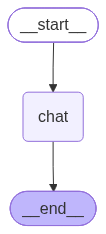

In [20]:
wk

In [21]:
initial = {
    'messages' : HumanMessage(content='what is organic chemistry')
}

In [22]:
result = wk.invoke(initial,config=config)

In [23]:
print(result['__interrupt__'])

[Interrupt(value={'type': 'approval', 'description': 'allow the agent to use llm or not', 'approval': 'y/n?'}, id='92ee107fc9ff33d8b7533487e6f81514', response_schema=None)]


In [24]:
final = wk.invoke(Command(resume='y'),config=config)

In [25]:
print(final['messages'][-1].content)

Hello there! That's a great question.

While the provided text focuses on the topic of "Solutions" and discusses concepts like abnormal molar mass using examples like ethanoic acid (an organic compound) and benzene (an organic solvent), it doesn't explicitly define "organic chemistry" as a branch of chemistry.

However, I can certainly explain what organic chemistry is for you:

**Organic chemistry is the branch of chemistry that studies the structure, properties, composition, reactions, and preparation of carbon-containing compounds.**

Here are a few key points about it:

*   **Central Role of Carbon:** Carbon is unique because it can form stable bonds with itself in long chains, rings, and complex structures, and also with many other elements (especially hydrogen, oxygen, nitrogen, sulfur, and halogens). This ability leads to an incredibly vast number of possible organic compounds.
*   **Life's Chemistry:** Organic chemistry is essentially the chemistry of life, as all known living 

In [26]:
from langchain.messages import RemoveMessage

In [27]:
x = final['messages']
len(x)

2